In [1]:
import pandas as pd

#Group raw ECG classes into four major groups

Rhythm_to_group = {
  #sinus bradycardia
  'SB':'SB',
  #Atrial fibrillation/flutter
  'AFIB':'AFIB',
  'AF':'AFIB',
  #Generalized supraventricular tachycardia(GSVT)
  'ST':'GSVT',
  'SVT':'GSVT',
  'AT':'GSVT',
  'AVNRT':'GSVT',
  'AVRT':'GSVT',
  'SAAWR':'GSVT',
  #Sinus rhythm
  'SR':'SR',
  'SI':'SR',
  'SA':'SR'
}

In [2]:
#Load dataset

df = pd.read_excel('/content/Diagnostics.xlsx')

In [3]:
#Data manipulation

df.head()

,FileName,Rhythm,Beat,PatientAge,Gender,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,QOnset,QOffset,TOffset
0,MUSE_20180113_171327_27000,AFIB,RBBB TWC,85,MALE,117,234,114,356,496,81,-27,19,208,265,386
1,MUSE_20180112_073319_29000,SB,TWC,59,FEMALE,52,52,92,432,401,76,42,8,215,261,431
2,MUSE_20180111_165520_97000,SA,NONE,20,FEMALE,67,67,82,382,403,88,20,11,224,265,415
3,MUSE_20180113_121940_44000,SB,NONE,66,MALE,53,53,96,456,427,34,3,9,219,267,447
4,MUSE_20180112_122850_57000,AF,STDD STTC,73,FEMALE,162,162,114,252,413,68,-40,26,228,285,354


In [4]:
df.shape

(10646, 16)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10646 entries, 0 to 10645
Data columns (total 16 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   FileName         10646 non-null  object
 1   Rhythm           10646 non-null  object
 2   Beat             10646 non-null  object
 3   PatientAge       10646 non-null  int64 
 4   Gender           10646 non-null  object
 5   VentricularRate  10646 non-null  int64 
 6   AtrialRate       10646 non-null  int64 
 7   QRSDuration      10646 non-null  int64 
 8   QTInterval       10646 non-null  int64 
 9   QTCorrected      10646 non-null  int64 
 10  RAxis            10646 non-null  int64 
 11  TAxis            10646 non-null  int64 
 12  QRSCount         10646 non-null  int64 
 13  QOnset           10646 non-null  int64 
 14  QOffset          10646 non-null  int64 
 15  TOffset          10646 non-null  int64 
dtypes: int64(12), object(4)
memory usage: 1.3+ MB


In [6]:
#check missing values

df.isnull().sum()

,0
FileName,0
Rhythm,0
Beat,0
PatientAge,0
Gender,0
VentricularRate,0
AtrialRate,0
QRSDuration,0
QTInterval,0
QTCorrected,0


In [7]:
#check duplicates

df.duplicated().sum()

np.int64(0)

In [8]:
#drop duplicates

df.drop_duplicates()

,FileName,Rhythm,Beat,PatientAge,Gender,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,QOnset,QOffset,TOffset
0,MUSE_20180113_171327_27000,AFIB,RBBB TWC,85,MALE,117,234,114,356,496,81,-27,19,208,265,386
1,MUSE_20180112_073319_29000,SB,TWC,59,FEMALE,52,52,92,432,401,76,42,8,215,261,431
2,MUSE_20180111_165520_97000,SA,NONE,20,FEMALE,67,67,82,382,403,88,20,11,224,265,415
3,MUSE_20180113_121940_44000,SB,NONE,66,MALE,53,53,96,456,427,34,3,9,219,267,447
4,MUSE_20180112_122850_57000,AF,STDD STTC,73,FEMALE,162,162,114,252,413,68,-40,26,228,285,354
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10641,MUSE_20181222_204306_99000,SVT,NONE,80,FEMALE,196,73,168,284,513,258,244,32,177,261,319
10642,MUSE_20181222_204309_22000,SVT,NONE,81,FEMALE,162,81,162,294,482,110,-75,27,173,254,320
10643,MUSE_20181222_204310_31000,SVT,NONE,39,MALE,152,92,152,340,540,250,38,25,208,284,378
10644,MUSE_20181222_204312_58000,SVT,NONE,76,MALE,175,178,128,310,529,98,-83,29,205,269,360


In [9]:
#View all original labels

print('Unique rhythm labels:')
print(sorted(df['Rhythm'].dropna().unique()))

Unique rhythm labels:
['AF', 'AFIB', 'AT', 'AVNRT', 'AVRT', 'SA', 'SAAWR', 'SB', 'SR', 'ST', 'SVT']


In [10]:
#Map Rhythm to Rhtym group

df['Rhythm_group'] = df['Rhythm'].map(Rhythm_to_group)

In [11]:
#Count unmapped rhythm

unmapped = df[df['Rhythm_group'].isna()]
print(f"\nmapped records: {len(df) - len(unmapped)}")
print(f"unmapped records: len(unmapped)")

if len(unmapped) > 0:
  print('\nunmapped rhythm labels:')
  print(sorted(unmapped['Rhythm'].unique()))


mapped records: 10646
unmapped records: len(unmapped)


In [12]:
from logging import exception
#Save the updated file

try:
  df.to_excel('Diagnostics_grouped.xlsx', index=False)
  print('\nGrouped dataset saved as Diagnostics_grouped.xlsx')
except exception as e:
  print(f"Error: {e}")


Grouped dataset saved as Diagnostics_grouped.xlsx


In [13]:
#Display grouped class counts

print('\nGrouped rhythm counts')
print(df['Rhythm_group'].value_counts(dropna=False))


Grouped rhythm counts
Rhythm_group
SB      3889
GSVT    2307
AFIB    2225
SR      2225
Name: count, dtype: int64


In [14]:
#Load grouped dataset
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

grouped_df = pd.read_excel('/content/Diagnostics_grouped.xlsx')

In [15]:
##Exploratory data analysis

#Basic information

print(f"Data info: \n{grouped_df.info()}")
print(f"Descriptive statistics: \n{grouped_df.describe()}")
print(f"Data shape: \n{grouped_df.shape}")
print(f"First five rows: \n{grouped_df.head()}")
print(f"Column list: \n{grouped_df.columns.to_list()}")

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10646 entries, 0 to 10645
Data columns (total 17 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   FileName         10646 non-null  object
 1   Rhythm           10646 non-null  object
 2   Beat             10646 non-null  object
 3   PatientAge       10646 non-null  int64 
 4   Gender           10646 non-null  object
 5   VentricularRate  10646 non-null  int64 
 6   AtrialRate       10646 non-null  int64 
 7   QRSDuration      10646 non-null  int64 
 8   QTInterval       10646 non-null  int64 
 9   QTCorrected      10646 non-null  int64 
 10  RAxis            10646 non-null  int64 
 11  TAxis            10646 non-null  int64 
 12  QRSCount         10646 non-null  int64 
 13  QOnset           10646 non-null  int64 
 14  QOffset          10646 non-null  int64 
 15  TOffset          10646 non-null  int64 
 16  Rhythm_group     10646 non-null  object
dtypes: int64(12), object(5)
memory 

In [16]:
# Handling missing values

grouped_df.isnull().sum()

,0
FileName,0
Rhythm,0
Beat,0
PatientAge,0
Gender,0
VentricularRate,0
AtrialRate,0
QRSDuration,0
QTInterval,0
QTCorrected,0


In [17]:
#Handling duplicates

grouped_df.duplicated().sum()

np.int64(0)

In [18]:
#Numerical and categorical features

num_cols = grouped_df.select_dtypes(include=np.number).columns.to_list()
cat_cols = grouped_df.select_dtypes(exclude=np.number).columns.to_list()

print(f"Numerical features: \n{num_cols}")
print(f"Categorical features: \n{cat_cols}")

Numerical features: 
['PatientAge', 'VentricularRate', 'AtrialRate', 'QRSDuration', 'QTInterval', 'QTCorrected', 'RAxis', 'TAxis', 'QRSCount', 'QOnset', 'QOffset', 'TOffset']
Categorical features: 
['FileName', 'Rhythm', 'Beat', 'Gender', 'Rhythm_group']


In [19]:
# Descriptive statistics of numerical and categorical columns

print(grouped_df[num_cols].describe())
print(grouped_df[cat_cols].describe())

         PatientAge  VentricularRate   AtrialRate   QRSDuration    QTInterval  \
count  10646.000000     10646.000000  10646.00000  10646.000000  10646.000000   
mean      59.186831        84.136107     92.57787     90.989292    384.150855   
std       18.030019        34.455349     60.09394     17.479540     59.226289   
min        4.000000        34.000000      0.00000     18.000000    114.000000   
25%       49.000000        57.000000     57.00000     80.000000    344.000000   
50%       62.000000        73.000000     72.00000     88.000000    390.000000   
75%       72.000000       104.000000    106.00000     98.000000    426.000000   
max       98.000000       263.000000    535.00000    256.000000    736.000000   

        QTCorrected         RAxis         TAxis      QRSCount        QOnset  \
count  10646.000000  10646.000000  10646.000000  10646.000000  10646.000000   
mean     434.154048     39.620609     44.637704     13.839470    219.260567   
std       39.354182     41.212648

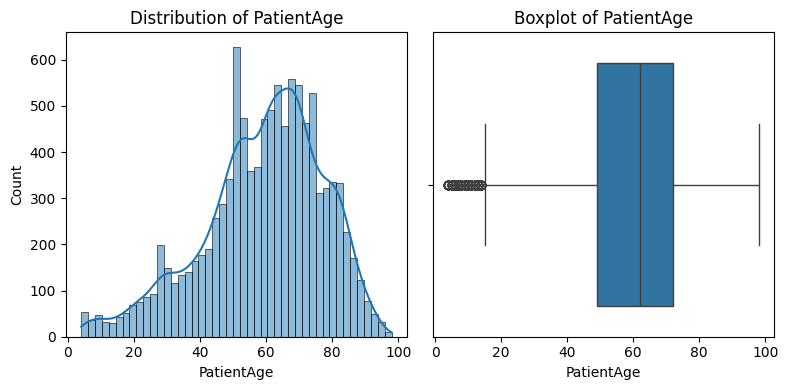

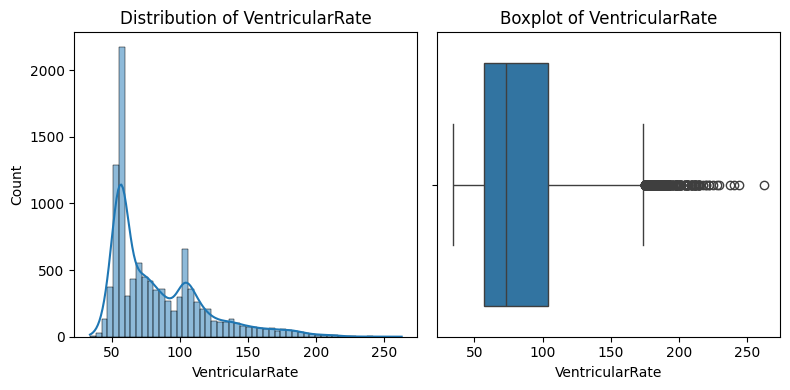

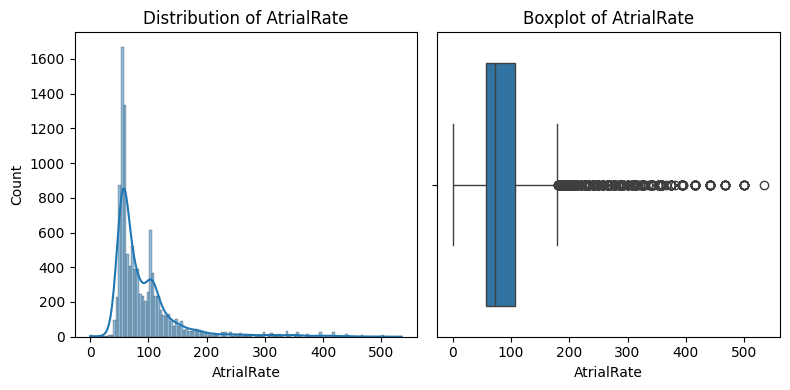

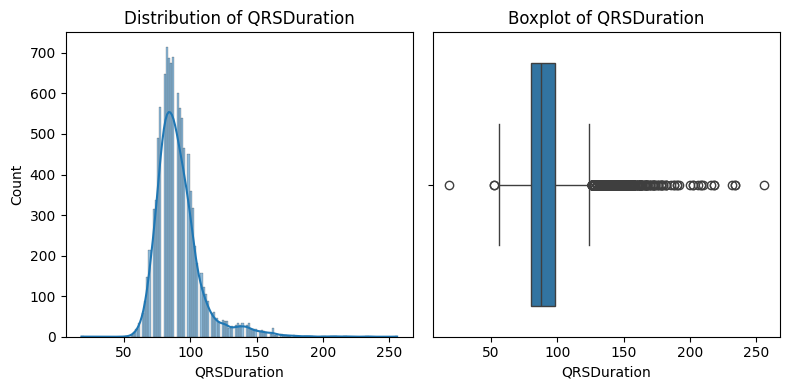

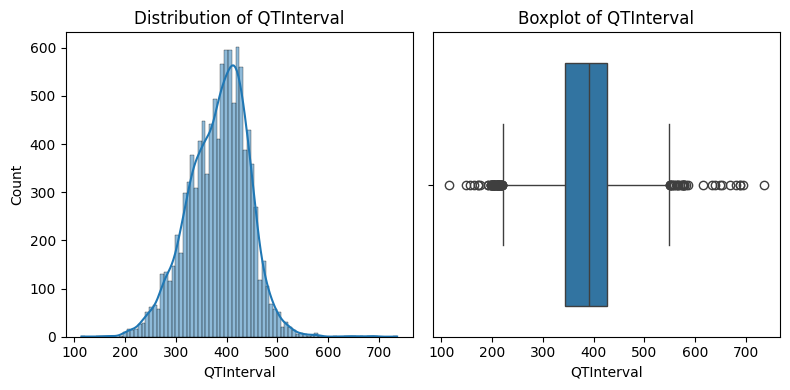

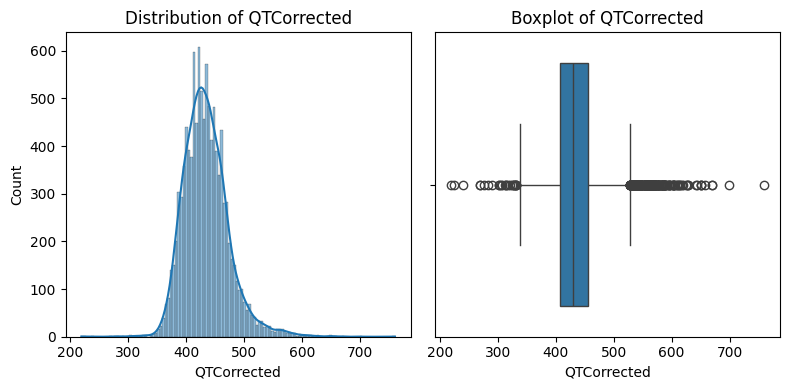

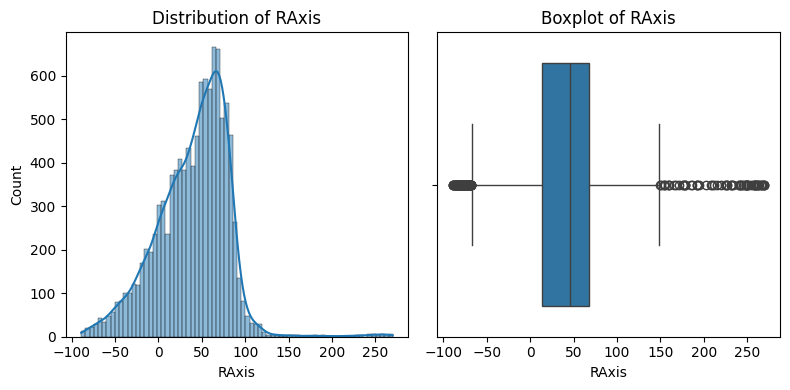

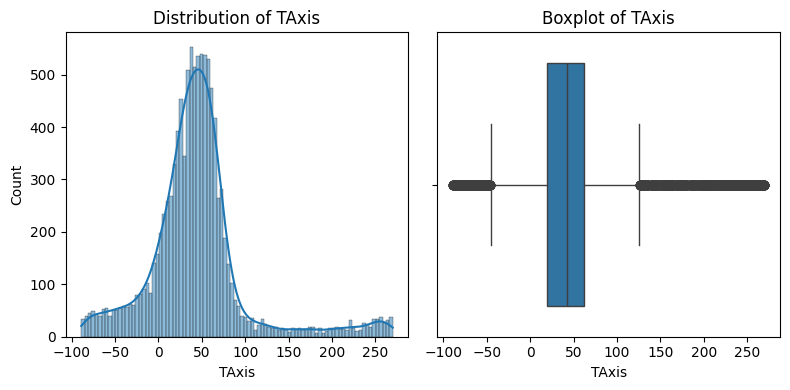

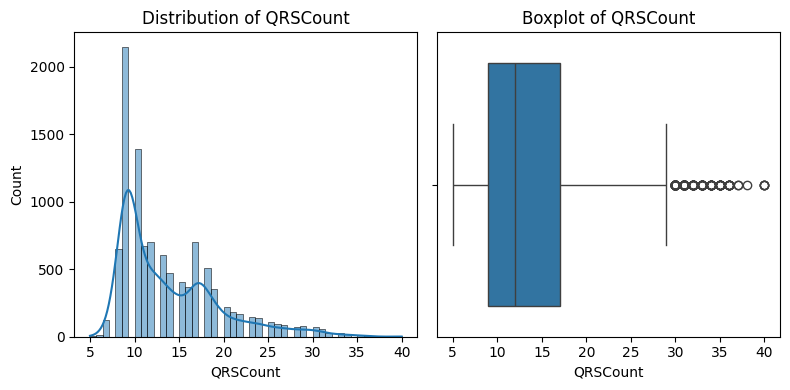

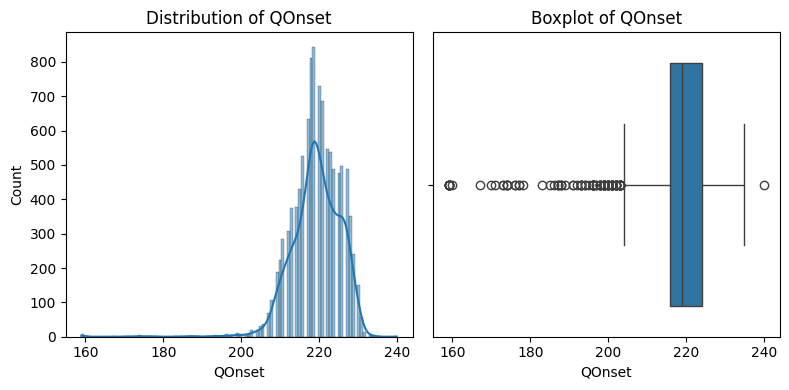

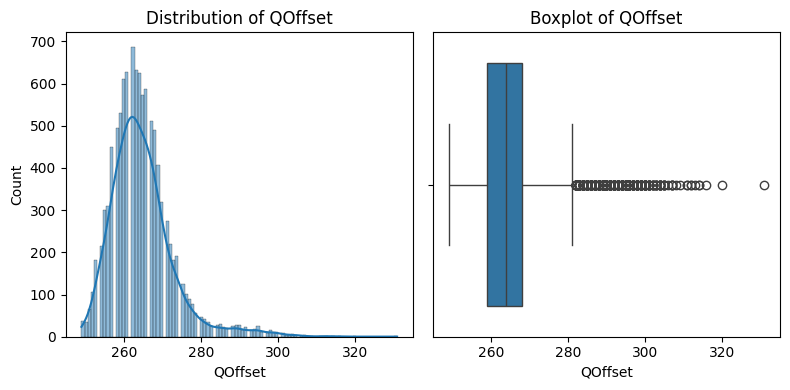

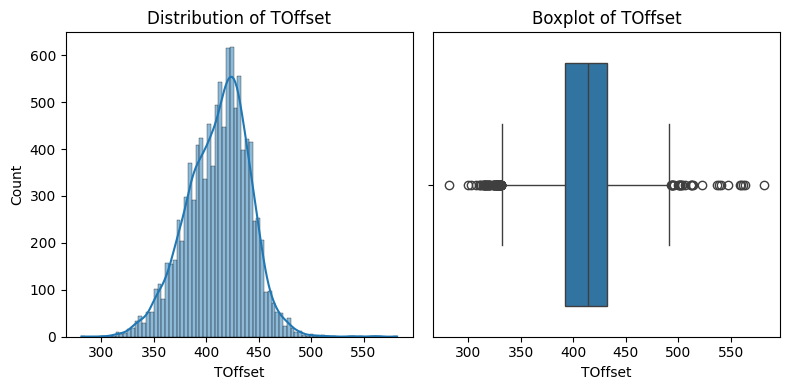

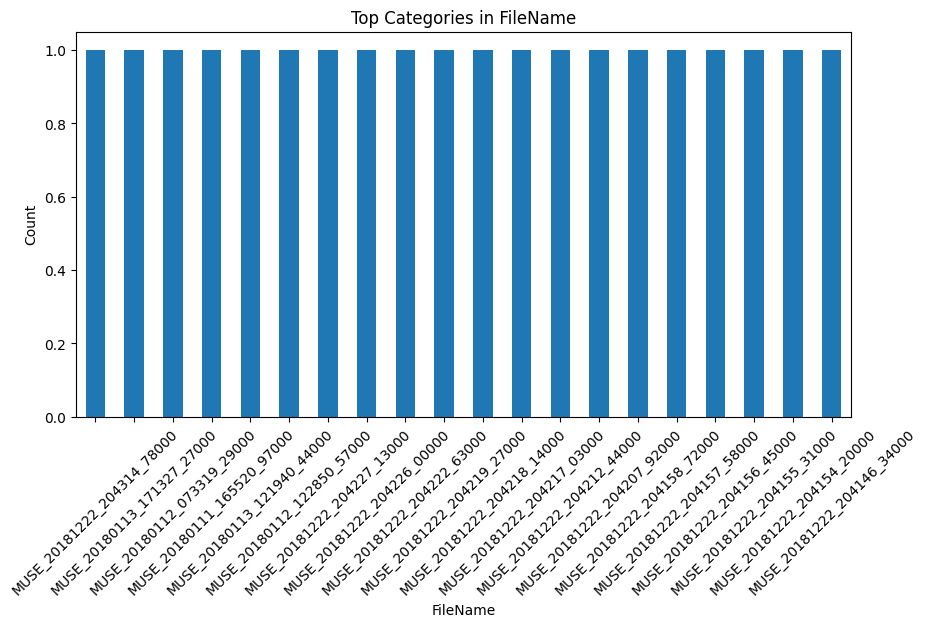

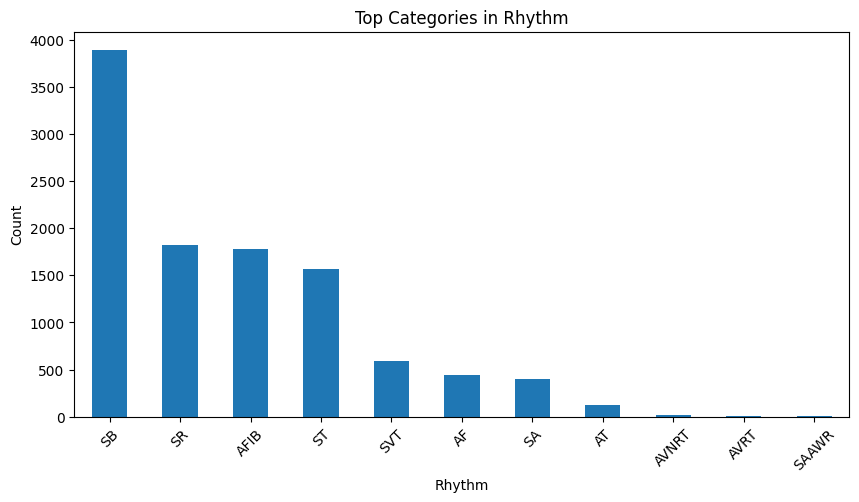

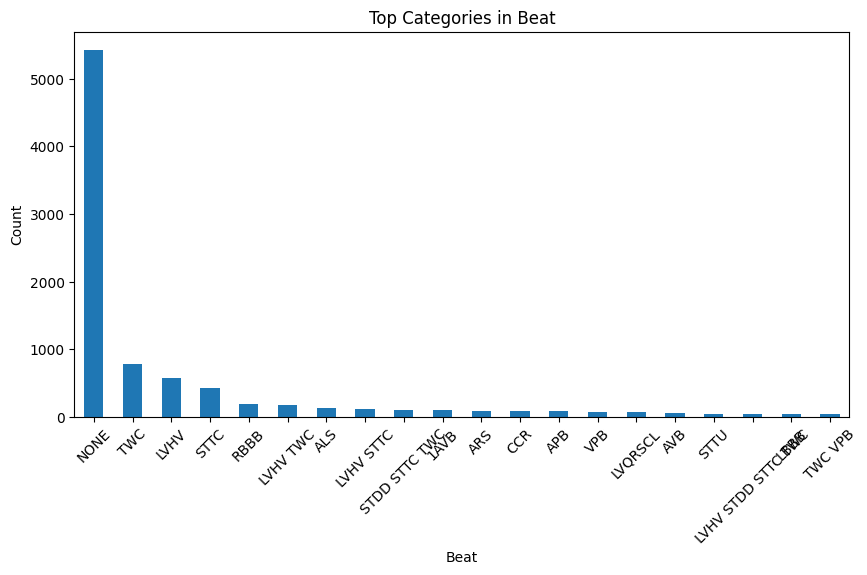

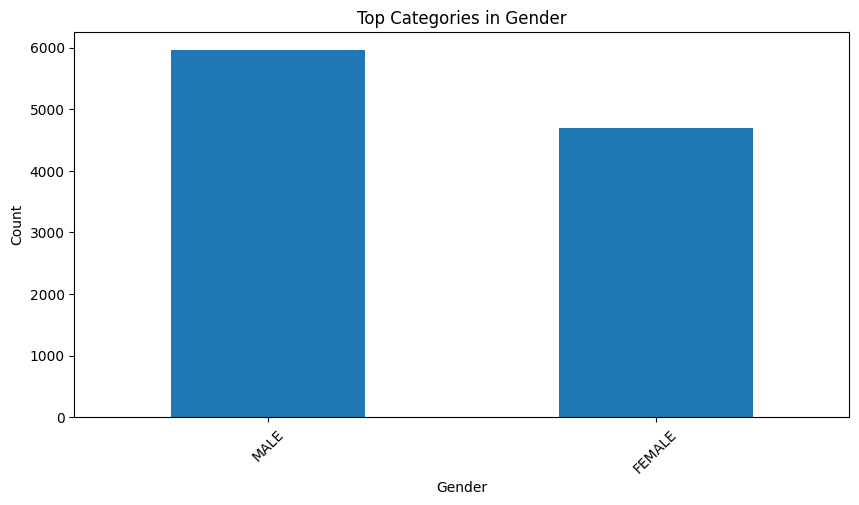

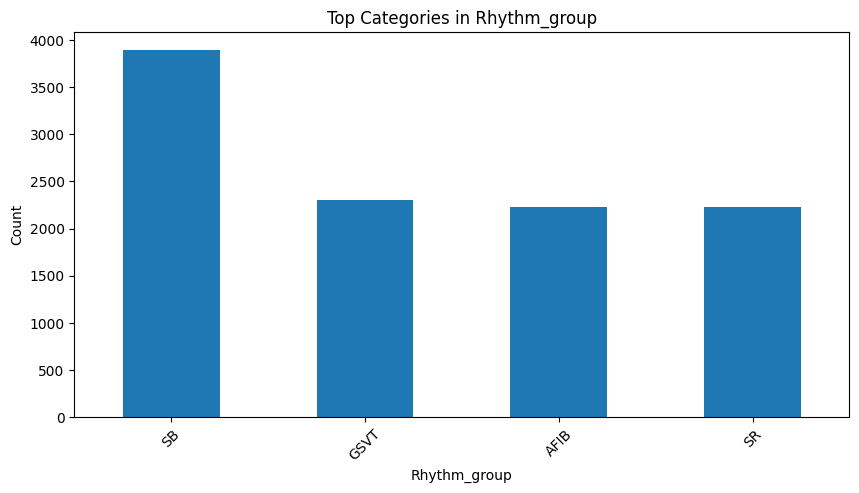

In [20]:
# Distribution of numerical features

for col in num_cols:
    plt.figure(figsize=(8,4))

    plt.subplot(1,2,1)
    sns.histplot(df[col], kde=True)
    plt.title(f"Distribution of {col}")

    plt.subplot(1,2,2)
    sns.boxplot(x=df[col])
    plt.title(f"Boxplot of {col}")

    plt.tight_layout()
    plt.show()

# Categorical analysis

for col in cat_cols:
    plt.figure(figsize=(10,5))

    df[col].value_counts().head(20).plot(
        kind='bar'
    )

    plt.title(f"Top Categories in {col}")
    plt.ylabel("Count")
    plt.xticks(rotation=45)
    plt.show()

In [21]:
# Outlier detection

Q1 = grouped_df[num_cols].quantile(0.25)
Q3 = grouped_df[num_cols].quantile(0.75)
IQR = Q3 - Q1

Lower_bound = Q1 - 1.5*IQR
Upper_bound = Q3 + 1.5*IQR

Outliers =  grouped_df[(grouped_df[num_cols] < Lower_bound) | (grouped_df[num_cols] > Upper_bound)]

print(f"Number of outliers: \n{len(Outliers)}")

Number of outliers: 
10646



RHYTHM GROUP COUNTS
Rhythm_group
SB      3889
GSVT    2307
AFIB    2225
SR      2225
Name: count, dtype: int64


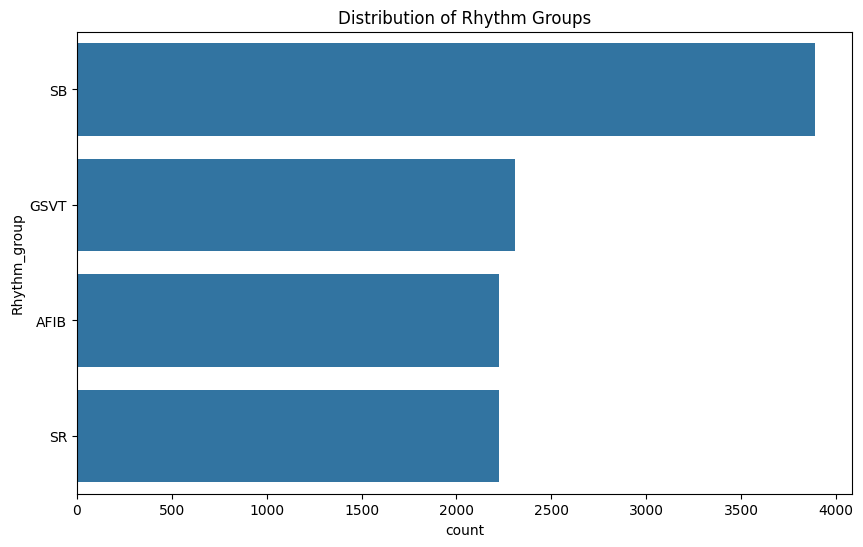


MEAN VALUES BY RHYTHM GROUP
              PatientAge  VentricularRate  AtrialRate  QRSDuration  \
Rhythm_group                                                         
AFIB           72.900674        99.306966  143.453933    93.684494   
GSVT           55.442133       127.160381  122.794972    88.229736   
SB             58.339676        55.022885   55.275906    93.318077   
SR             50.836404        75.241348   75.569888    87.084944   

              QTInterval  QTCorrected      RAxis      TAxis   QRSCount  \
Rhythm_group                                                             
AFIB          362.610337   451.880449  37.326742  50.956404  16.302022   
GSVT          320.323364   457.071955  45.259211  48.597313  20.923277   
SB            433.338133   413.304191  36.182823  40.513757   9.058627   
SR            385.898427   429.107865  42.076854  41.421573  12.388315   

                  QOnset     QOffset     TOffset  
Rhythm_group                                      
AFI

In [22]:
#Rhythm group analysis

if "Rhythm_group" in grouped_df.columns:

    print("\nRHYTHM GROUP COUNTS")
    print(grouped_df["Rhythm_group"].value_counts())

    plt.figure(figsize=(10,6))
    sns.countplot(
        y="Rhythm_group",
        data=grouped_df,
        order=grouped_df["Rhythm_group"].value_counts().index
    )
    plt.title("Distribution of Rhythm Groups")
    plt.show()

    # Numerical summary by rhythm group
    group_summary = grouped_df.groupby("Rhythm_group")[num_cols].mean()

    print("\nMEAN VALUES BY RHYTHM GROUP")
    print(group_summary)

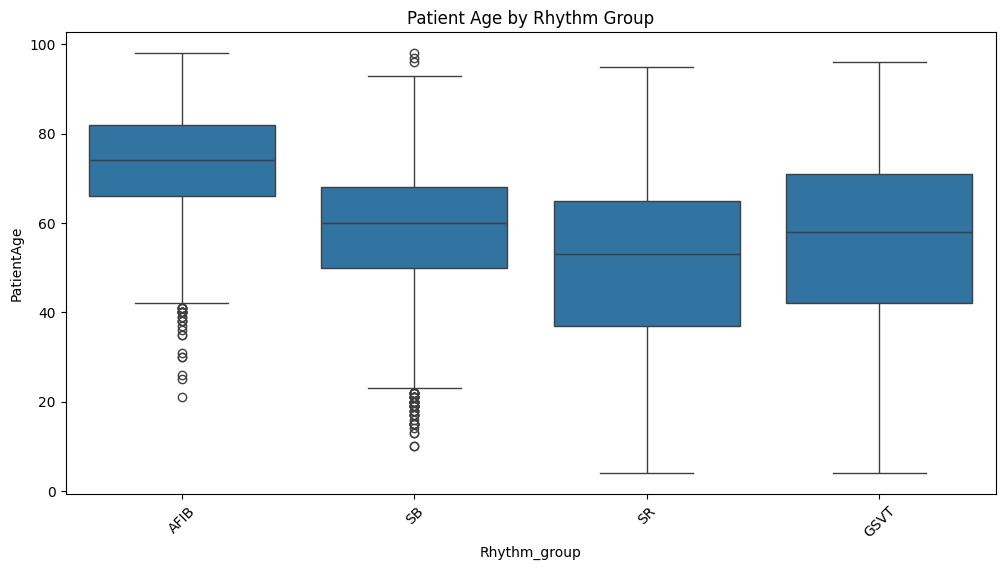

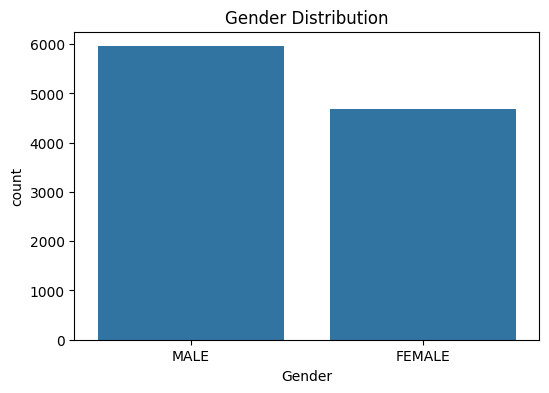

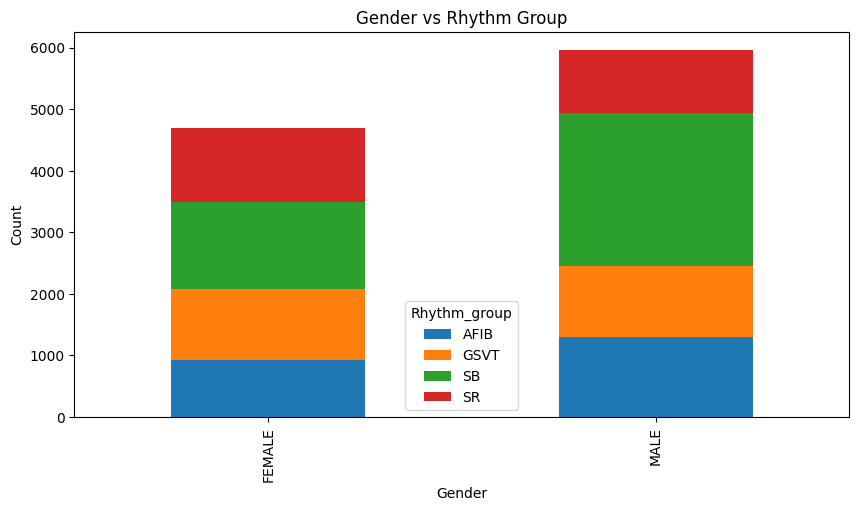

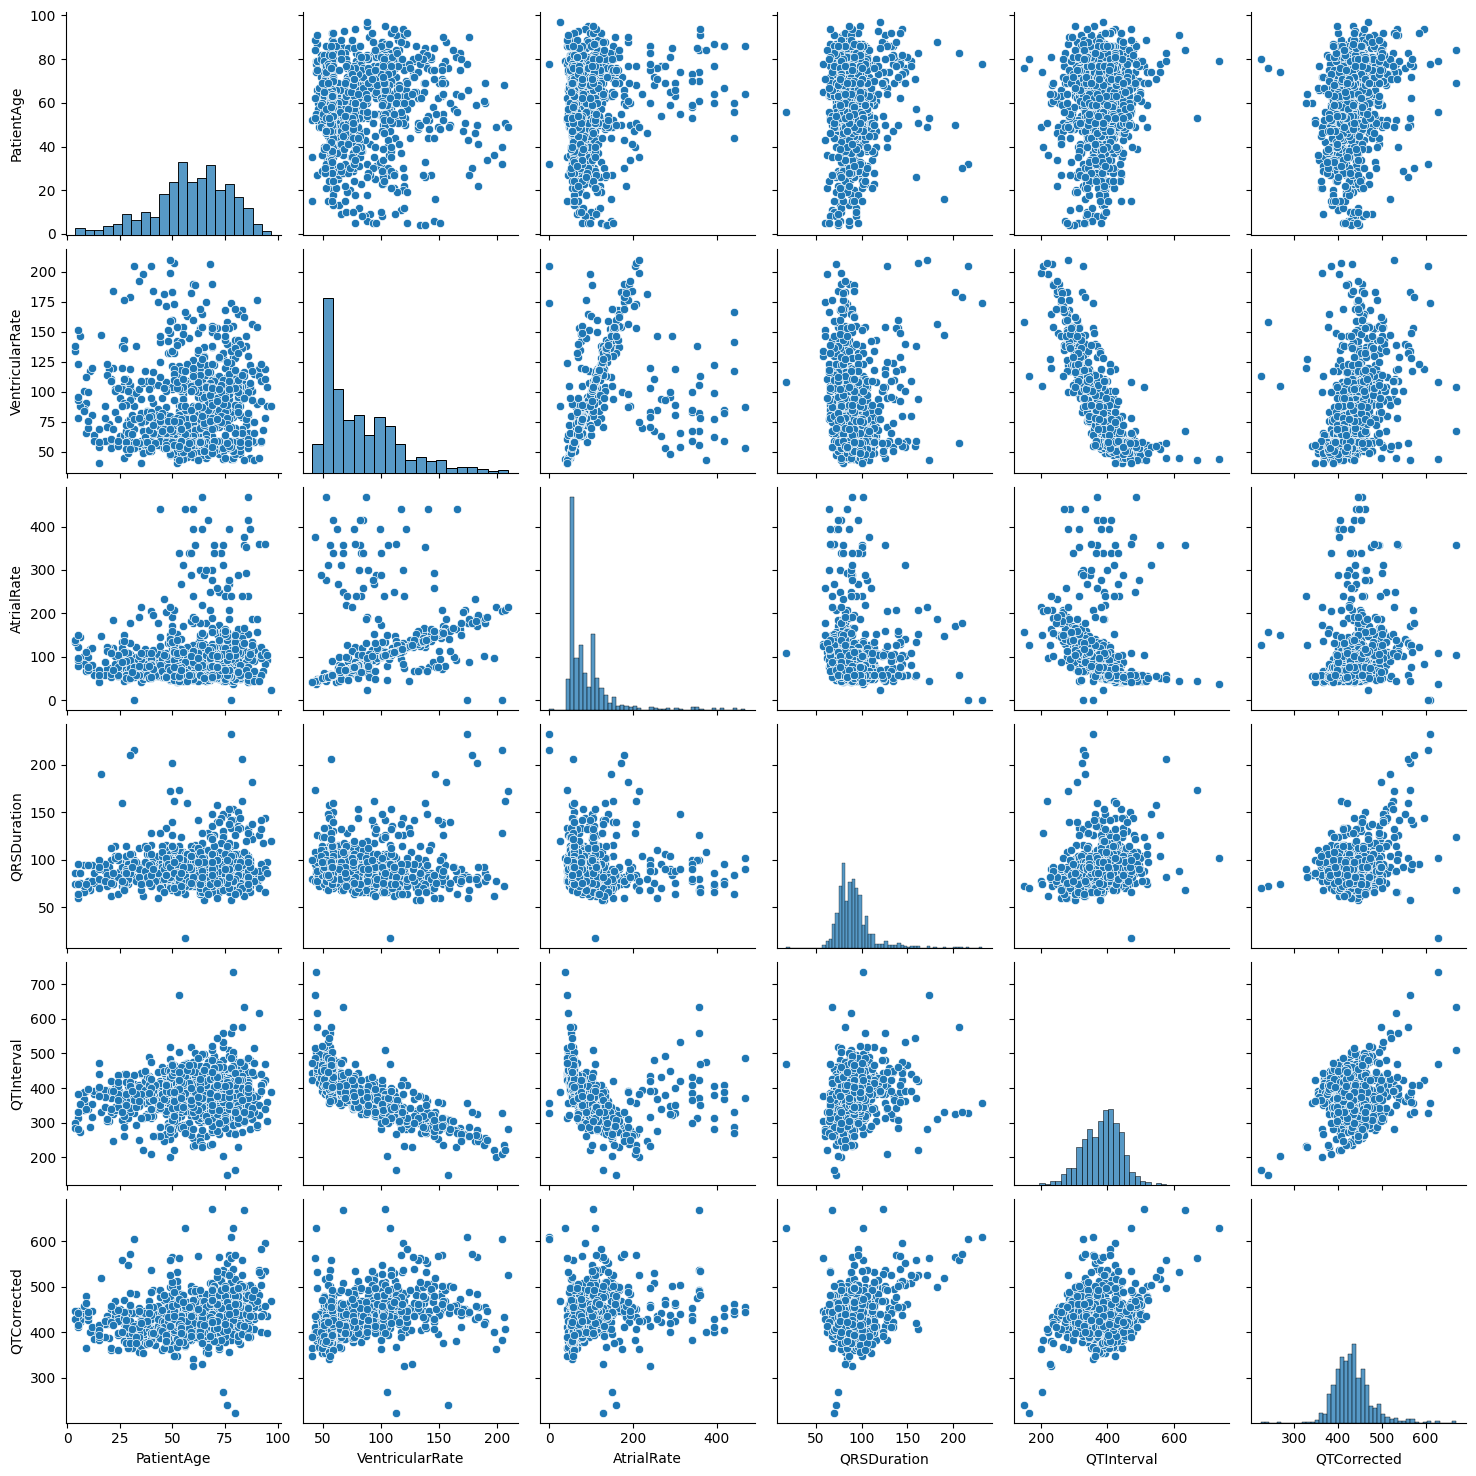

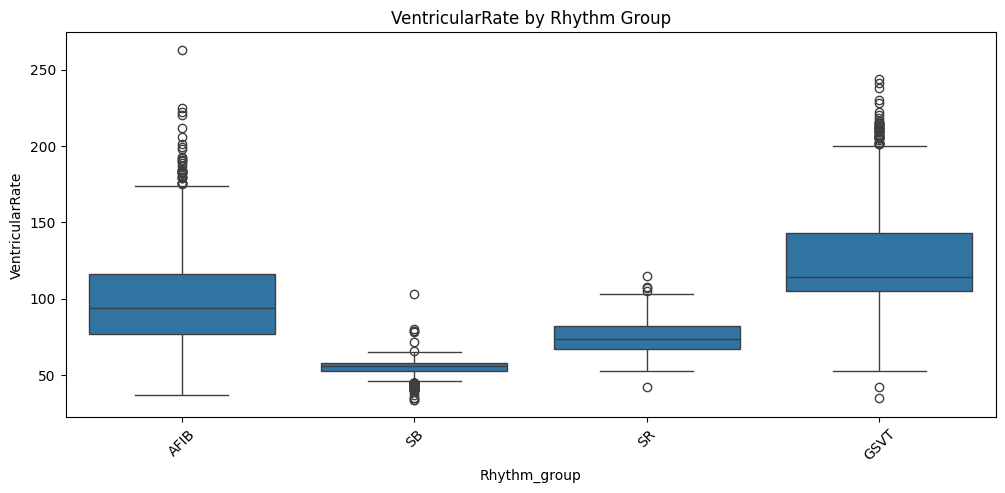

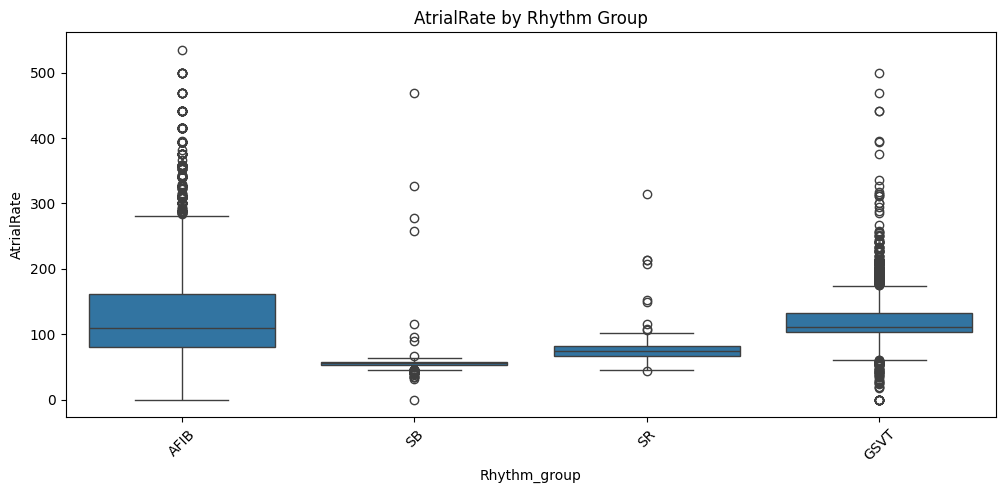

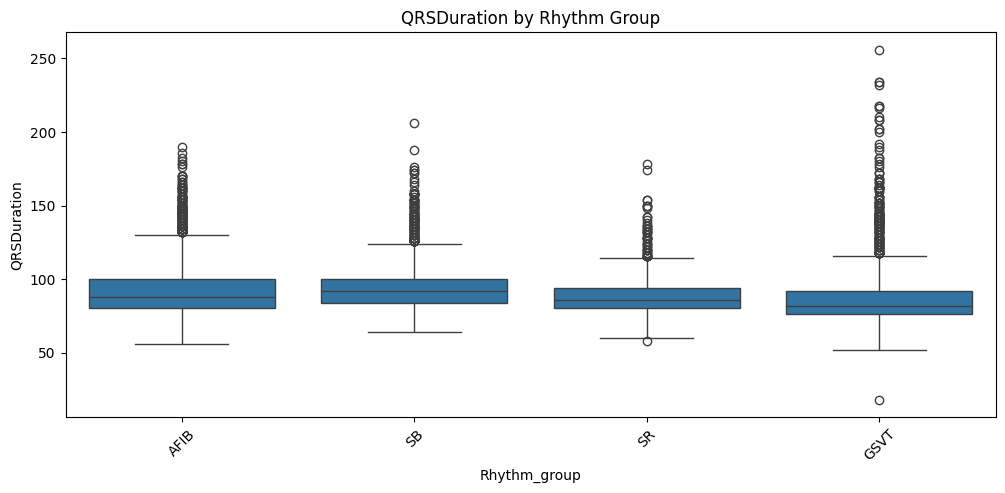

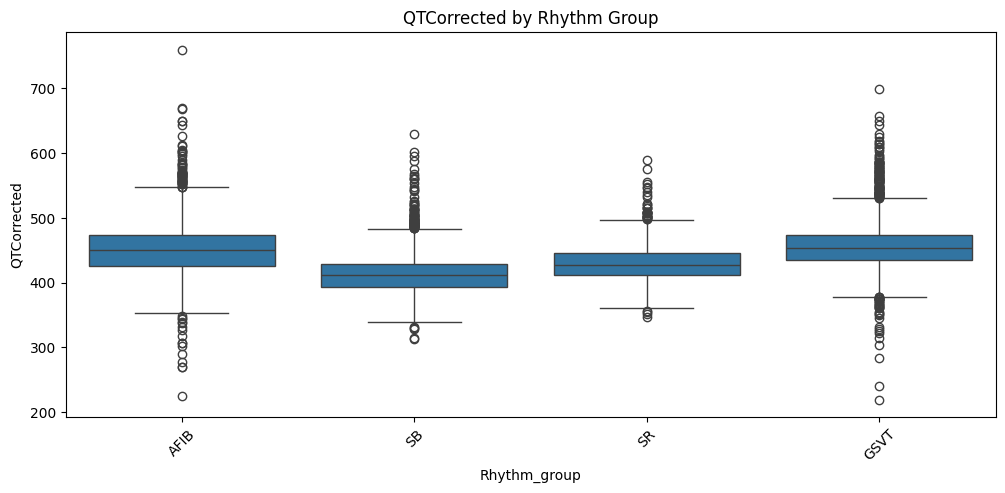


EDA COMPLETED SUCCESSFULLY


In [23]:
# Age distribution by rhythm group

if "PatientAge" in grouped_df.columns and "Rhythm_group" in grouped_df.columns:

    plt.figure(figsize=(12,6))

    sns.boxplot(
        x="Rhythm_group",
        y="PatientAge",
        data=grouped_df
    )

    plt.xticks(rotation=45)
    plt.title("Patient Age by Rhythm Group")
    plt.show()
# Gender analysis

if "Gender" in grouped_df.columns:

    plt.figure(figsize=(6,4))

    sns.countplot(
        x="Gender",
        data=grouped_df
    )

    plt.title("Gender Distribution")
    plt.show()

    if "Rhythm_group" in grouped_df.columns:

        gender_rhythm = pd.crosstab(
            grouped_df["Gender"],
            grouped_df["Rhythm_group"]
        )

        gender_rhythm.plot(
            kind="bar",
            stacked=True,
            figsize=(10,5)
        )

        plt.title("Gender vs Rhythm Group")
        plt.ylabel("Count")
        plt.show()

# Pairplot (sampled for speed)
# ------------------------------------------
sample_df = grouped_df.sample(
    min(1000, len(grouped_df)),
    random_state=42
)

selected_cols = [
    'PatientAge',
    'VentricularRate',
    'AtrialRate',
    'QRSDuration',
    'QTInterval',
    'QTCorrected'
]

available_cols = [c for c in selected_cols if c in df.columns]

sns.pairplot(
    sample_df[available_cols]
)
plt.show()

# ------------------------------------------
# Feature Relationships with Rhythm Group
# ------------------------------------------
if "Rhythm_group" in grouped_df.columns:

    for col in [
        'VentricularRate',
        'AtrialRate',
        'QRSDuration',
        'QTCorrected'
    ]:

        if col in grouped_df.columns:

            plt.figure(figsize=(12,5))

            sns.boxplot(
                x="Rhythm_group",
                y=col,
                data=grouped_df
            )

            plt.xticks(rotation=45)
            plt.title(f"{col} by Rhythm Group")
            plt.show()

print("\nEDA COMPLETED SUCCESSFULLY")

In [24]:
## Feature engineering

from sklearn.preprocessing import LabelEncoder
import pandas as pd
import numpy as np

# Reload grouped_df to ensure a consistent starting state for feature engineering
grouped_df = pd.read_excel('/content/Diagnostics_grouped.xlsx')

# Age features

grouped_df['Age_group'] = pd.cut(grouped_df['PatientAge'], bins=[18,40,60,80,120], labels=['young_adult', 'middle_age', 'senior', 'elderly'])

#Heart rate feature

grouped_df["Rate_Difference"] = (
    grouped_df["VentricularRate"] -
    grouped_df["AtrialRate"]
)

grouped_df["Rate_Ratio"] = (
    grouped_df["VentricularRate"] /
    (grouped_df["AtrialRate"] + 1e-6)
)

grouped_df["Rate_Absolute_Diff"] = (
    np.abs(grouped_df["Rate_Difference"])
)

#ECG interval features

grouped_df["QT_QRS_Ratio"] = (
    grouped_df["QTInterval"] /
    (grouped_df["QRSDuration"] + 1e-6)
)

grouped_df["QTc_QRS_Ratio"] = (
    grouped_df["QTCorrected"] /
    (grouped_df["QRSDuration"] + 1e-6)
)

grouped_df["QT_QTc_Difference"] = (
    grouped_df["QTCorrected"] -
    grouped_df["QTInterval"]
)

# Arhythmia indicators

grouped_df["Tachycardia"] = (
    grouped_df["VentricularRate"] > 100
).astype(int)

grouped_df["Bradycardia"] = (
    grouped_df["VentricularRate"] < 60
).astype(int)

grouped_df["Wide_QRS"] = (
    grouped_df["QRSDuration"] > 120
).astype(int)

grouped_df["Long_QTc"] = (
    grouped_df["QTCorrected"] > 450
).astype(int)

# ECG composite features

grouped_df["Electrical_Stress_Index"] = (
    grouped_df["QTCorrected"] *
    grouped_df["VentricularRate"]
)

grouped_df["Conduction_Index"] = (
    grouped_df["QRSDuration"] *
    grouped_df["QTCorrected"]
)

# Interaction features

grouped_df["Age_x_QTc"] = (
    grouped_df["PatientAge"] *
    grouped_df["QTCorrected"]
)

grouped_df["Age_x_QRS"] = (
    grouped_df["PatientAge"] *
    grouped_df["QRSDuration"]
)

grouped_df["Rate_x_QTc"] = (
    grouped_df["VentricularRate"] *
    grouped_df["QTCorrected"]
)

# Statistical features

ecg_cols = [
    "VentricularRate",
    "AtrialRate",
    "QRSDuration",
    "QTInterval",
    "QTCorrected"
]

grouped_df["ECG_Mean"] = grouped_df[ecg_cols].mean(axis=1)

grouped_df["ECG_STD"] = grouped_df[ecg_cols].std(axis=1)

grouped_df["ECG_Max"] = grouped_df[ecg_cols].max(axis=1)

grouped_df["ECG_Min"] = grouped_df[ecg_cols].min(axis=1)

grouped_df["ECG_Range"] = (
    grouped_df["ECG_Max"] -
    grouped_df["ECG_Min"]
)

# One hot encoding for categorical columns

categorical_columns = [
    "Rhythm",
    "Beat",
    "Gender",
    "Age_group"
]

grouped_df = pd.get_dummies(
    grouped_df,
    columns=categorical_columns,
    drop_first=True
)

# Convert all boolean columns (created by get_dummies) to int (0 or 1)
for col in grouped_df.columns:
    if grouped_df[col].dtype == bool:
        grouped_df[col] = grouped_df[col].astype(int)

# Log transform

for col in [
    "QTCorrected",
    "QRSDuration",
    "VentricularRate"
]:

    if col in grouped_df.columns:

        grouped_df[f"{col}_Log"] = np.log1p(
            grouped_df[col]
        )



# Define target

target = "Rhythm_group"

# Drop target, identifier (FileName), and original categorical columns that have been one-hot encoded
columns_to_drop = [target, 'FileName', 'Rhythm', 'Beat', 'Gender', 'Age_group']
X = grouped_df.drop(columns=columns_to_drop, errors='ignore')

# Use LabelEncoder for the target variable 'y'
# Ensure grouped_df[target] is used
label_encoder = LabelEncoder() # Define label_encoder
y = label_encoder.fit_transform(grouped_df[target])

print("New Shape:", grouped_df.shape)

grouped_df.head()

New Shape: (10646, 792)


/tmp/ipykernel_748/2217952307.py:147: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  grouped_df[f"{col}_Log"] = np.log1p(
/tmp/ipykernel_748/2217952307.py:147: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `newframe = frame.copy()`
  grouped_df[f"{col}_Log"] = np.log1p(
/tmp/ipykernel_748/2217952307.py:147: PerformanceWarning: DataFrame is highly fragmented.  This is usually the result of calling `frame.insert` many times, which has poor performance.  Consider joining all columns at once using pd.concat(axis=1) instead. To get a de-fragmented frame, use `ne

,FileName,PatientAge,VentricularRate,AtrialRate,QRSDuration,QTInterval,QTCorrected,RAxis,TAxis,QRSCount,...,Beat_VPE,Beat_WAVN,Beat_WPW,Gender_MALE,Age_group_middle_age,Age_group_senior,Age_group_elderly,QTCorrected_Log,QRSDuration_Log,VentricularRate_Log
0,MUSE_20180113_171327_27000,85,117,234,114,356,496,81,-27,19,...,0,0,0,1,0,0,1,6.208590,4.744932,4.770685
1,MUSE_20180112_073319_29000,59,52,52,92,432,401,76,42,8,...,0,0,0,0,1,0,0,5.996452,4.532599,3.970292
2,MUSE_20180111_165520_97000,20,67,67,82,382,403,88,20,11,...,0,0,0,0,0,0,0,6.001415,4.418841,4.219508
3,MUSE_20180113_121940_44000,66,53,53,96,456,427,34,3,9,...,0,0,0,1,0,1,0,6.059123,4.574711,3.988984
4,MUSE_20180112_122850_57000,73,162,162,114,252,413,68,-40,26,...,0,0,0,0,0,1,0,6.025866,4.744932,5.093750


In [25]:
##Model development

from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score
import numpy as np
import pandas as pd

num_imputer = SimpleImputer(strategy='median')
cat_imputer = SimpleImputer(strategy='most_frequent') # This imputer is no longer used for object columns below
Scaler = StandardScaler()


print(f"Columns in X before final encoding/imputation: {X.columns.tolist()}")
print(f"Dtypes of X before final encoding/imputation:\n{X.dtypes}")

# Convert any boolean columns to int (0 or 1) so they are treated as numerical
bool_cols = X.select_dtypes(include=bool).columns
if not bool_cols.empty:
    for col_name in bool_cols: # Iterate over the names of boolean columns
        X[col_name] = X[col_name].astype(int) # Convert each Series individually

# Identify numerical and object-type categorical columns within this new X
num_columns = X.select_dtypes(include=np.number).columns
object_cat_columns = X.select_dtypes(include='object').columns # Explicitly target 'object' dtypes

# Impute numerical columns
if not num_columns.empty:
    X[num_columns] = num_imputer.fit_transform(X[num_columns])

# Impute object-type categorical columns with their mode and then one-hot encode them
if not object_cat_columns.empty:
    print(f"Detected object categorical columns for imputation and encoding: {object_cat_columns.tolist()}")
    for col in object_cat_columns:
        # Fill missing values with the mode using pandas' native fillna
        X[col] = X[col].fillna(X[col].mode()[0])
    # After imputation, one-hot encode these imputed object columns
    X = pd.get_dummies(X, columns=object_cat_columns, drop_first=True)

# Final conversion of all features to float to be absolutely sure for SMOTE
X = X.astype(float)

print(f"Columns in X after all processing: {X.columns.tolist()}")
print(f"Final Dtypes of X columns:\n{X.dtypes}")

# Final check for any remaining object columns (should be none after .astype(float))
non_numeric_cols_final = [col for col in X.columns if X[col].dtype == 'object']
if non_numeric_cols_final:
    raise ValueError(f"Remaining non-numeric object columns after all processing: {non_numeric_cols_final}")

# train/validation/test split (70% train, 15% validation, 15% test)
X_train, X_temp, y_train, y_temp = train_test_split(X, y, test_size=0.3, stratify=y, random_state=42)
X_val, X_test, y_val, y_test = train_test_split(X_temp, y_temp, test_size=0.5, stratify=y_temp, random_state=42)


Columns in X before final encoding/imputation: ['PatientAge', 'VentricularRate', 'AtrialRate', 'QRSDuration', 'QTInterval', 'QTCorrected', 'RAxis', 'TAxis', 'QRSCount', 'QOnset', 'QOffset', 'TOffset', 'Rate_Difference', 'Rate_Ratio', 'Rate_Absolute_Diff', 'QT_QRS_Ratio', 'QTc_QRS_Ratio', 'QT_QTc_Difference', 'Tachycardia', 'Bradycardia', 'Wide_QRS', 'Long_QTc', 'Electrical_Stress_Index', 'Conduction_Index', 'Age_x_QTc', 'Age_x_QRS', 'Rate_x_QTc', 'ECG_Mean', 'ECG_STD', 'ECG_Max', 'ECG_Min', 'ECG_Range', 'Rhythm_AFIB', 'Rhythm_AT', 'Rhythm_AVNRT', 'Rhythm_AVRT', 'Rhythm_SA', 'Rhythm_SAAWR', 'Rhythm_SB', 'Rhythm_SR', 'Rhythm_ST', 'Rhythm_SVT', 'Beat_1AVB 2AVB1', 'Beat_1AVB ALS', 'Beat_1AVB ALS APB STDD STTC', 'Beat_1AVB ALS AQW LBBB', 'Beat_1AVB ALS AQW STTU TWC', 'Beat_1AVB ALS CR TWC', 'Beat_1AVB ALS LFBBB MIFW RBBB VPB', 'Beat_1AVB ALS RBBB TWC', 'Beat_1AVB ALS STDD STTC TWC', 'Beat_1AVB ALS STDD STTC TWC VPB', 'Beat_1AVB ALS STTC', 'Beat_1AVB ALS TWC', 'Beat_1AVB APB', 'Beat_1AVB APB

New shape of X_train after dropping constant columns: (7452, 632)
New shape of X_val after dropping constant columns: (1597, 632)
New shape of X_test after dropping constant columns: (1597, 632)
X_train columns before SMOTE: ['PatientAge', 'VentricularRate', 'AtrialRate', 'QRSDuration', 'QTInterval', 'QTCorrected', 'RAxis', 'TAxis', 'QRSCount', 'QOnset', 'QOffset', 'TOffset', 'Rate_Difference', 'Rate_Ratio', 'Rate_Absolute_Diff', 'QT_QRS_Ratio', 'QTc_QRS_Ratio', 'QT_QTc_Difference', 'Tachycardia', 'Bradycardia', 'Wide_QRS', 'Long_QTc', 'Electrical_Stress_Index', 'Conduction_Index', 'Age_x_QTc', 'Age_x_QRS', 'Rate_x_QTc', 'ECG_Mean', 'ECG_STD', 'ECG_Max', 'ECG_Min', 'ECG_Range', 'Rhythm_AFIB', 'Rhythm_AT', 'Rhythm_AVNRT', 'Rhythm_AVRT', 'Rhythm_SA', 'Rhythm_SAAWR', 'Rhythm_SB', 'Rhythm_SR', 'Rhythm_ST', 'Rhythm_SVT', 'Beat_1AVB 2AVB1', 'Beat_1AVB ALS', 'Beat_1AVB ALS APB STDD STTC', 'Beat_1AVB ALS AQW STTU TWC', 'Beat_1AVB ALS CR TWC', 'Beat_1AVB ALS LFBBB MIFW RBBB VPB', 'Beat_1AVB ALS

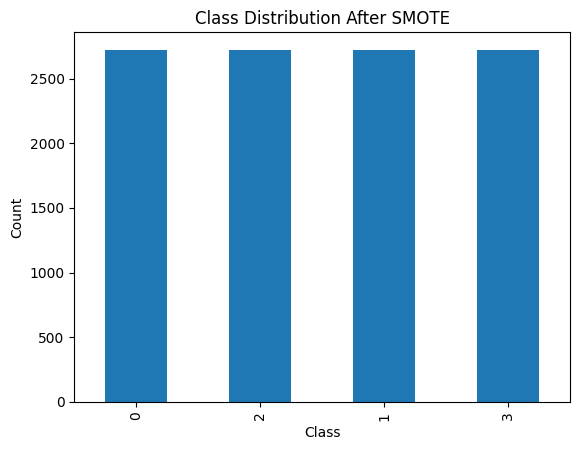

In [26]:
from imblearn.over_sampling import SMOTE
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Explicitly convert all columns in X_train to numeric, handling any remaining non-numeric types
for col in X_train.columns:
    if X_train[col].dtype == 'object':
        try:
            X_train[col] = pd.to_numeric(X_train[col])
        except ValueError as e:
            raise ValueError(f"Column '{col}' in X_train is still non-numeric and could not be converted: {e}") from e

# Re-check for any non-numeric columns after conversion attempt
non_numeric_cols_final_xtrain = X_train.select_dtypes(exclude=np.number).columns.tolist()
if non_numeric_cols_final_xtrain:
    raise ValueError(f"X_train still contains non-numeric columns: {non_numeric_cols_final_xtrain}")

# Identify constant columns in X_train
constant_columns = [col for col in X_train.columns if X_train[col].nunique() == 1]

if constant_columns:
    print(f"Warning: The following columns are constant in X_train and will be dropped: {constant_columns}")
    # Drop constant columns from all splits to maintain consistency
    X_train = X_train.drop(columns=constant_columns)
    X_val = X_val.drop(columns=constant_columns)
    X_test = X_test.drop(columns=constant_columns)
    print(f"New shape of X_train after dropping constant columns: {X_train.shape}")
    print(f"New shape of X_val after dropping constant columns: {X_val.shape}")
    print(f"New shape of X_test after dropping constant columns: {X_test.shape}")

print(f"X_train columns before SMOTE: {X_train.columns.tolist()}")

smote = SMOTE(random_state=42)
X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)

print(f"X_train_resampled columns after SMOTE: {X_train_resampled.columns.tolist()}")

# Identify missing columns
missing_cols = set(X_train.columns) - set(X_train_resampled.columns)
extra_cols = set(X_train_resampled.columns) - set(X_train.columns)

if missing_cols:
    print(f"Columns missing in X_train_resampled compared to X_train: {sorted(list(missing_cols))}")
if extra_cols:
    print(f"Columns extra in X_train_resampled compared to X_train: {sorted(list(extra_cols))}")


# Convert y_train_resampled to a pandas Series to use value_counts()
y_train_resampled_series = pd.Series(y_train_resampled)

y_train_resampled_series.value_counts()
y_train_resampled_series.value_counts().plot(kind='bar')
plt.title('Class Distribution After SMOTE')
plt.xlabel('Class')
plt.ylabel('Count')
plt.show()

In [27]:
print(f"Shape of X_train: {X_train.shape}")
print(f"Shape of X_train_resampled: {X_train_resampled.shape}")
print(f"Shape of X_val: {X_val.shape}")
print(f"Shape of X_test: {X_test.shape}")

Shape of X_train: (7452, 632)
Shape of X_train_resampled: (10888, 632)
Shape of X_val: (1597, 632)
Shape of X_test: (1597, 632)


In [28]:
## Train Random Forest Classifier, XGBoost and

from sklearn.ensemble import RandomForestClassifier
from xgboost import XGBClassifier
from sklearn.neighbors import KNeighborsClassifier

rf = RandomForestClassifier(
    n_estimators=500,
    max_depth=15,
    random_state=42,
    n_jobs=-1
)

rf.fit(
    X_train_resampled,
    y_train_resampled
)


xgb = XGBClassifier(
    n_estimators=500,
    learning_rate=0.05,
    max_depth=6,
    subsample=0.8,
    colsample_bytree=0.8,
    random_state=42,
    eval_metric='mlogloss'
)

xgb.fit(
    X_train_resampled,
    y_train_resampled
)

knn = KNeighborsClassifier(
    n_neighbors=5,
    weights="distance",
    metric="minkowski",
    p=2
)

knn.fit(
    X_train_resampled,
    y_train_resampled
)

KNeighborsClassifier(weights='distance')

Random Forest
Accuracy : 0.976205385097057
Precision: 0.9763838534787741
Recall   : 0.976205385097057
F1-score : 0.9761490043369063

Classification Report
              precision    recall  f1-score   support

           0       0.97      0.93      0.95       334
           1       0.94      0.97      0.95       346
           2       1.00      1.00      1.00       584
           3       0.99      0.99      0.99       333

    accuracy                           0.98      1597
   macro avg       0.97      0.97      0.97      1597
weighted avg       0.98      0.98      0.98      1597

XGBoost
Accuracy : 1.0
Precision: 1.0
Recall   : 1.0
F1-score : 1.0

Classification Report
              precision    recall  f1-score   support

           0       1.00      1.00      1.00       334
           1       1.00      1.00      1.00       346
           2       1.00      1.00      1.00       584
           3       1.00      1.00      1.00       333

    accuracy                           1.00    

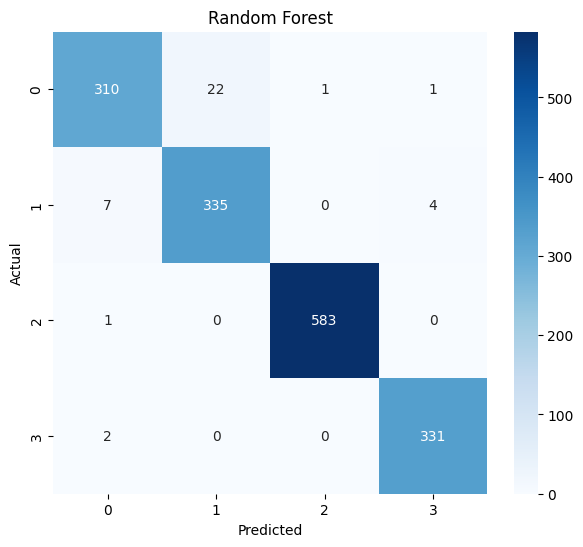

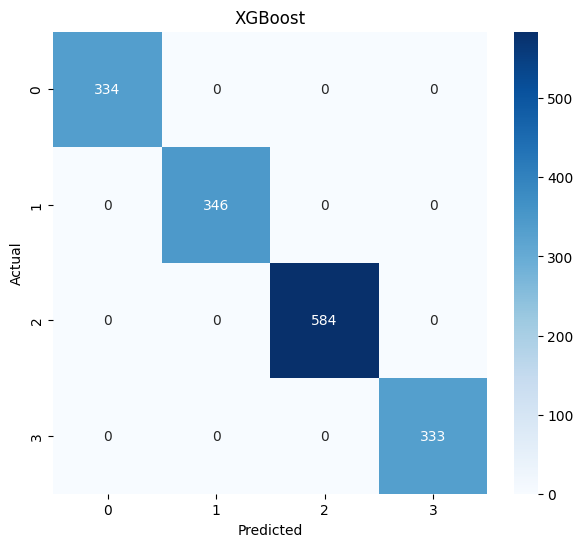

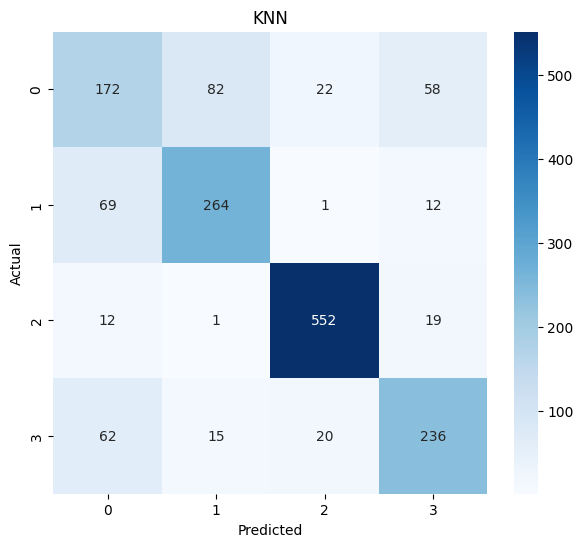

RF ROC-AUC: 0.9992991719466462
XGB ROC-AUC: 1.0
KNN ROC-AUC: 0.9089327015418915


In [29]:
## Model evaluation
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score,
    confusion_matrix,
    classification_report,
    roc_curve,
    auc
)

from sklearn.preprocessing import label_binarize
from sklearn.model_selection import cross_val_score

# Model predictions

rf_pred = rf.predict(X_test)

xgb_pred = xgb.predict(X_test)

knn_pred = knn.predict(X_test)

# Calculate performance metrics

def evaluate_model(model_name, y_true, y_pred):

    accuracy = accuracy_score(y_true, y_pred)

    precision = precision_score(
        y_true,
        y_pred,
        average='weighted'
    )

    recall = recall_score(
        y_true,
        y_pred,
        average='weighted'
    )

    f1 = f1_score(
        y_true,
        y_pred,
        average='weighted'
    )

    print("="*50)
    print(model_name)
    print("="*50)

    print("Accuracy :", accuracy)
    print("Precision:", precision)
    print("Recall   :", recall)
    print("F1-score :", f1)

    print("\nClassification Report")

    print(classification_report(
        y_true,
        y_pred
    ))

evaluate_model("Random Forest", y_test, rf_pred)

evaluate_model("XGBoost", y_test, xgb_pred)

evaluate_model("KNN", y_test, knn_pred)

# Confusion matrix

def plot_cm(model_name, y_true, y_pred):

    cm = confusion_matrix(
        y_true,
        y_pred
    )

    plt.figure(figsize=(7,6))

    sns.heatmap(
        cm,
        annot=True,
        fmt="d",
        cmap="Blues"
    )

    plt.title(model_name)

    plt.xlabel("Predicted")

    plt.ylabel("Actual")

    plt.show()

plot_cm("Random Forest", y_test, rf_pred)

plot_cm("XGBoost", y_test, xgb_pred)

plot_cm("KNN", y_test, knn_pred)

# ROC-AUC (multi-class)

classes = np.unique(y_test)

y_test_bin = label_binarize(
    y_test,
    classes=classes
)

rf_prob = rf.predict_proba(X_test)

rf_auc = roc_auc_score(
    y_test_bin,
    rf_prob,
    multi_class="ovr",
    average="weighted"
)

print("RF ROC-AUC:", rf_auc)

xgb_prob = xgb.predict_proba(X_test)

xgb_auc = roc_auc_score(
    y_test_bin,
    xgb_prob,
    multi_class="ovr",
    average="weighted"
)

print("XGB ROC-AUC:", xgb_auc)

knn_prob = knn.predict_proba(X_test)

knn_auc = roc_auc_score(
    y_test_bin,
    knn_prob,
    multi_class="ovr",
    average="weighted"
)

print("KNN ROC-AUC:", knn_auc)

In [30]:
## Cross validation (cv)

rf_cv = cross_val_score(
    rf,
    X,
    y,
    cv=5,
    scoring="f1_weighted"
)

xgb_cv = cross_val_score(
    xgb,
    X,
    y,
    cv=5,
    scoring="f1_weighted"
)

knn_cv = cross_val_score(
    knn,
    X,
    y,
    cv=5,
    scoring="f1_weighted"
)

print("RF CV:", rf_cv.mean())

print("XGB CV:", xgb_cv.mean())

print("KNN CV:", knn_cv.mean())

RF CV: 0.9717262340615533
XGB CV: 0.9974625778439339
KNN CV: 0.7672323878152033


In [31]:
## Performance comparison table

results = pd.DataFrame({

    "Model":[
        "Random Forest",
        "XGBoost",
        "KNN"
    ],

    "Accuracy":[

        accuracy_score(y_test, rf_pred),

        accuracy_score(y_test, xgb_pred),

        accuracy_score(y_test, knn_pred)

    ],

    "Precision":[

        precision_score(
            y_test,
            rf_pred,
            average="weighted"
        ),

        precision_score(
            y_test,
            xgb_pred,
            average="weighted"
        ),

        precision_score(
            y_test,
            knn_pred,
            average="weighted"
        )

    ],

    "Recall":[

        recall_score(
            y_test,
            rf_pred,
            average="weighted"
        ),

        recall_score(
            y_test,
            xgb_pred,
            average="weighted"
        ),

        recall_score(
            y_test,
            knn_pred,
            average="weighted"
        )

    ],

    "F1":[

        f1_score(
            y_test,
            rf_pred,
            average="weighted"
        ),

        f1_score(
            y_test,
            xgb_pred,
            average="weighted"
        ),

        f1_score(
            y_test,
            knn_pred,
            average="weighted"
        )

    ],

    "ROC-AUC":[
        rf_auc,
        xgb_auc,
        knn_auc
    ]

})

print(results)

           Model  Accuracy  Precision    Recall        F1   ROC-AUC
0  Random Forest  0.976205   0.976384  0.976205  0.976149  0.999299
1        XGBoost  1.000000   1.000000  1.000000  1.000000  1.000000
2            KNN  0.766437   0.762874  0.766437  0.764426  0.908933


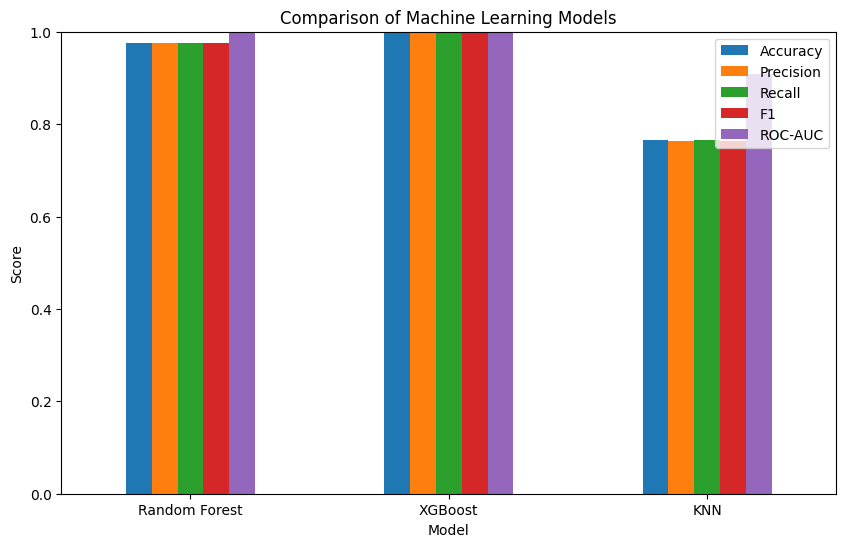

In [32]:
## Visualization of results

results.plot(
    x="Model",
    y=["Accuracy","Precision","Recall","F1","ROC-AUC"],
    kind="bar",
    figsize=(10,6)
)

plt.ylabel("Score")

plt.ylim(0,1)

plt.title("Comparison of Machine Learning Models")

plt.xticks(rotation=0)

plt.show()

In [33]:
## Mathews Correlation coefficient

from sklearn.metrics import matthews_corrcoef

print("RF MCC :", matthews_corrcoef(y_test, rf_pred))

print("XGB MCC:", matthews_corrcoef(y_test, xgb_pred))

print("KNN MCC:", matthews_corrcoef(y_test, knn_pred))

RF MCC : 0.9675810284939775
XGB MCC: 1.0
KNN MCC: 0.6806176333076441


In [36]:
# ==========================================================
# FINAL MODEL TRAINING & SAVE OBJECTS
# ==========================================================

import os
import joblib
import pandas as pd

from sklearn.preprocessing import StandardScaler, LabelEncoder
from sklearn.model_selection import train_test_split
from xgboost import XGBClassifier

# ----------------------------------------------------------
# TARGET COLUMN
# ----------------------------------------------------------

target = "Rhythm"

# ----------------------------------------------------------
# FEATURES
# ----------------------------------------------------------

X = df.drop(columns=[target])
y = df[target]

# Save feature names
selected_features = X.columns.tolist()

# ----------------------------------------------------------
# LABEL ENCODER
# ----------------------------------------------------------

label_encoder = LabelEncoder()
y_encoded = label_encoder.fit_transform(y)

# ----------------------------------------------------------
# TRAIN TEST SPLIT
# ----------------------------------------------------------

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y_encoded,
    test_size=0.20,
    random_state=42,
    stratify=y_encoded
)

# ----------------------------------------------------------
# STANDARD SCALER
# ----------------------------------------------------------

scaler = StandardScaler()

X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# ----------------------------------------------------------
# BEST MODEL
# ----------------------------------------------------------

best_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.8,
    colsample_bytree=0.8,
    objective="multi:softprob",
    eval_metric="mlogloss",
    random_state=42
)

best_model.fit(X_train_scaled, y_train)

# ----------------------------------------------------------
# CREATE MODELS FOLDER
# ----------------------------------------------------------

os.makedirs("models", exist_ok=True)

# ----------------------------------------------------------
# SAVE OBJECTS
# ----------------------------------------------------------

joblib.dump(best_model, "models/best_model.pkl")
joblib.dump(scaler, "models/scaler.pkl")
joblib.dump(label_encoder, "models/label_encoder.pkl")
joblib.dump(selected_features, "models/selected_features.pkl")

print("="*50)
print("SUCCESS!")
print("="*50)
print("best_model.pkl saved")
print("scaler.pkl saved")
print("label_encoder.pkl saved")
print("selected_features.pkl saved")